# ODE, sistemi dinamici e metodi numerici

Notebook di esercitazione — **versione con soluzioni**.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (7, 4.5)


## 1. Euler esplicito e convergenza

In [17]:
def euler(f, t0, y0, h, nsteps):
    t = t0
    y = np.array(y0, dtype=float)
    ts = [t]
    ys = [y.copy()]
    for _ in range(nsteps):
        y = y + h*np.asarray(f(t, y))
        t += h
        ts.append(t)
        ys.append(y.copy())
    return np.asarray(ts), np.asarray(ys)


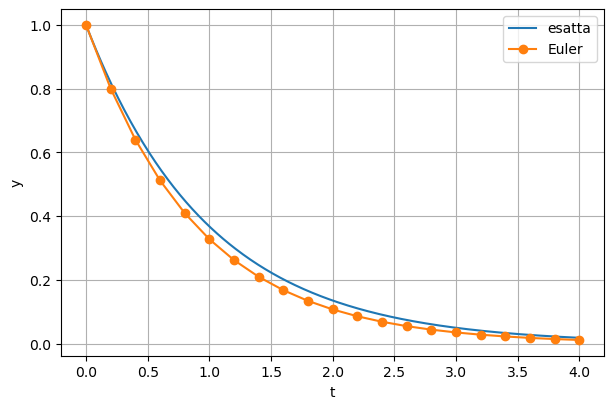

In [18]:
f = lambda t, y: -y
h = 0.2
T = 4.0
ts, ys = euler(f, 0.0, 1.0, h, int(T/h))
texact = np.linspace(0, T, 400)

plt.plot(texact, np.exp(-texact), label='esatta')
plt.plot(ts, ys, 'o-', label='Euler')
plt.xlabel('t'); plt.ylabel('y'); plt.legend(); plt.grid(True)
plt.show()


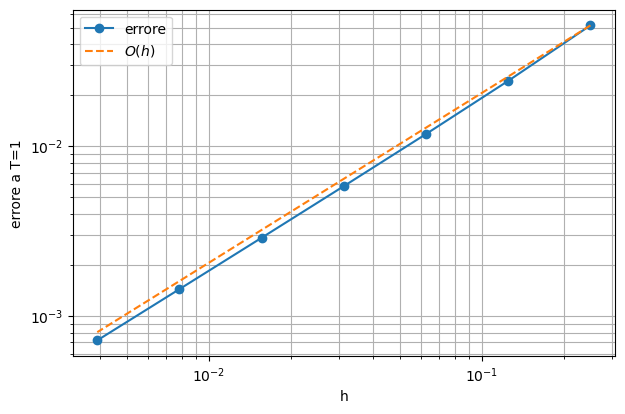

Ordini sperimentali: [1.08461589 1.03976932 1.01931612 1.00952309 1.00472864 1.0023562 ]


In [19]:
hs = 2.0 ** (-np.arange(2, 9))
errors = []
for h in hs:
    nsteps = int(round(1.0/h))
    ts, ys = euler(f, 0.0, 1.0, h, nsteps)
    errors.append(abs(float(ys[-1]) - np.exp(-1.0)))
errors = np.asarray(errors)

plt.loglog(hs, errors, 'o-', label='errore')
plt.loglog(hs, errors[0]*(hs/hs[0]), '--', label=r'$O(h)$')
plt.xlabel('h'); plt.ylabel('errore a T=1'); plt.legend(); plt.grid(True, which='both')
plt.show()

print('Ordini sperimentali:', np.log(errors[:-1]/errors[1:]) / np.log(hs[:-1]/hs[1:]))


## 2. Stabilità assoluta di Euler

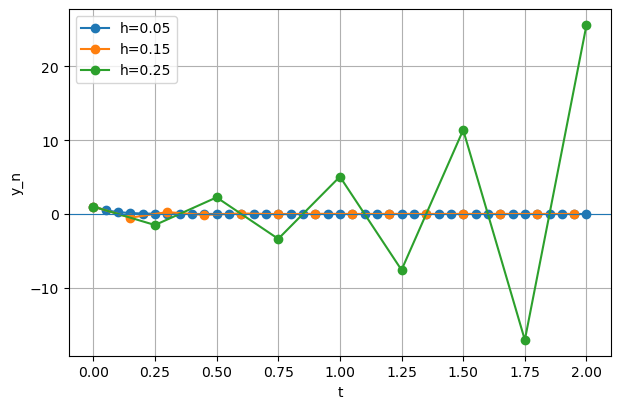

Per lambda=-10 la condizione è |1-10h|<1, quindi 0<h<0.2.


In [20]:
lam = -10.0
f_stab = lambda t, y: lam*y

for h in [0.05, 0.15, 0.25]:
    T = 2.0
    ts, ys = euler(f_stab, 0.0, 1.0, h, int(T/h))
    plt.plot(ts, ys, 'o-', label=f'h={h}')
plt.axhline(0.0, linewidth=0.8)
plt.xlabel('t'); plt.ylabel('y_n'); plt.legend(); plt.grid(True)
plt.show()

print('Per lambda=-10 la condizione è |1-10h|<1, quindi 0<h<0.2.')


## 3. RK4

In [21]:
def rk4(f, t0, y0, h, nsteps):
    t = t0
    y = np.array(y0, dtype=float)
    ts = [t]
    ys = [y.copy()]
    for _ in range(nsteps):
        k1 = np.asarray(f(t, y))
        k2 = np.asarray(f(t+h/2, y+h*k1/2))
        k3 = np.asarray(f(t+h/2, y+h*k2/2))
        k4 = np.asarray(f(t+h, y+h*k3))
        y = y + h*(k1+2*k2+2*k3+k4)/6
        t += h
        ts.append(t)
        ys.append(y.copy())
    return np.asarray(ts), np.asarray(ys)


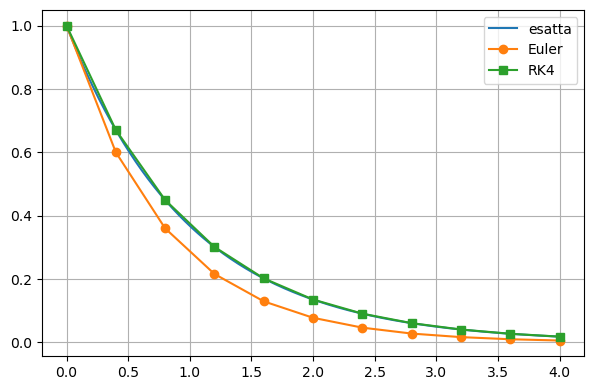

In [22]:
h = 0.4
T = 4.0
ts_e, ys_e = euler(f, 0.0, 1.0, h, int(T/h))
ts_r, ys_r = rk4(f, 0.0, 1.0, h, int(T/h))
t = np.linspace(0, T, 400)
plt.plot(t, np.exp(-t), label='esatta')
plt.plot(ts_e, ys_e, 'o-', label='Euler')
plt.plot(ts_r, ys_r, 's-', label='RK4')
plt.legend(); plt.grid(True); plt.show()


## 4. Sistema dinamico planare

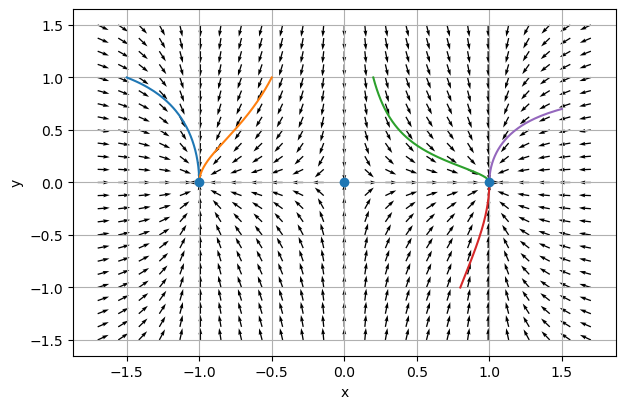

In [23]:
def planar_system(t, z):
    x, y = z
    return np.array([x-x**3, -y])

x = np.linspace(-1.7, 1.7, 25)
y = np.linspace(-1.5, 1.5, 25)
X, Y = np.meshgrid(x, y)
U = X-X**3
V = -Y
N = np.sqrt(U**2+V**2)
N[N==0] = 1
plt.quiver(X, Y, U/N, V/N)

for z0 in [[-1.5,1.0],[-0.5,1.0],[0.2,1.0],[0.8,-1.0],[1.5,0.7]]:
    ts, zs = rk4(planar_system, 0.0, z0, 0.02, 600)
    plt.plot(zs[:,0], zs[:,1])
plt.scatter([-1,0,1],[0,0,0], zorder=5)
plt.xlabel('x'); plt.ylabel('y'); plt.grid(True); plt.show()


## 5. Lotka--Volterra

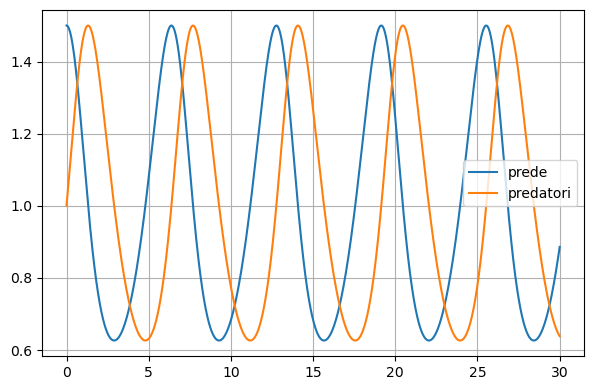

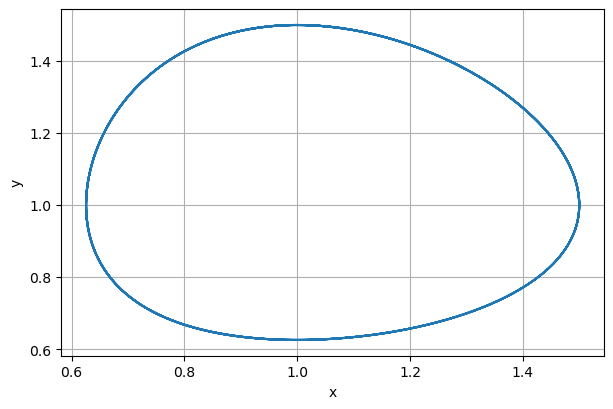

In [24]:
def lotka_volterra(t, z):
    x, y = z
    return np.array([x-x*y, x*y-y])

def invariant_lv(z):
    x, y = z[...,0], z[...,1]
    return x - np.log(x) + y - np.log(y)

T=30.0; h=0.02; z0=[1.5,1.0]
ts, zs = rk4(lotka_volterra, 0.0, z0, h, int(T/h))

plt.plot(ts, zs[:,0], label='prede')
plt.plot(ts, zs[:,1], label='predatori')
plt.legend(); plt.grid(True); plt.show()

plt.plot(zs[:,0], zs[:,1])
plt.xlabel('x'); plt.ylabel('y'); plt.grid(True); plt.show()


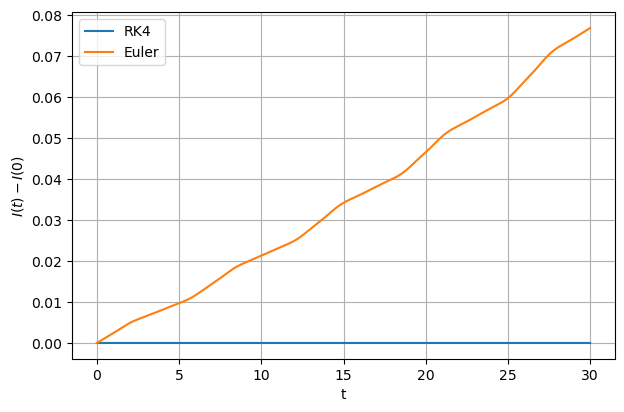

In [25]:
ts_e, zs_e = euler(lotka_volterra, 0.0, z0, 0.02, int(T/0.02))
I_r = invariant_lv(zs)
I_e = invariant_lv(zs_e)
plt.plot(ts, I_r-I_r[0], label='RK4')
plt.plot(ts_e, I_e-I_e[0], label='Euler')
plt.xlabel('t'); plt.ylabel(r'$I(t)-I(0)$'); plt.legend(); plt.grid(True); plt.show()


## 6. Van der Pol

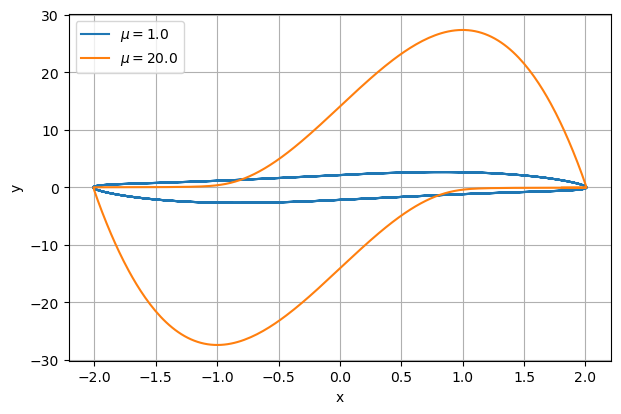

Per mu grande compaiono scale temporali molto diverse: il metodo esplicito richiede passi piccoli per stabilità/accuratezza.


In [26]:
def van_der_pol(mu):
    def f(t, z):
        x, y = z
        return np.array([y, mu*(1-x**2)*y-x])
    return f

for mu, h, T in [(1.0,0.01,30.0),(20.0,0.001,40.0)]:
    ts, zs = rk4(van_der_pol(mu), 0.0, [2.0,0.0], h, int(T/h))
    plt.plot(zs[:,0], zs[:,1], label=fr'$\mu={mu}$')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.grid(True); plt.show()

print('Per mu grande compaiono scale temporali molto diverse: il metodo esplicito richiede passi piccoli per stabilità/accuratezza.')


## 7. Sistemi Hamiltoniani e integratori simplettici

In [27]:
def harmonic(t, z):
    q, p = z
    return np.array([p, -q])

def energy(z):
    q, p = z[...,0], z[...,1]
    return 0.5*(q*q+p*p)

def symplectic_euler(q0, p0, h, nsteps):
    q=float(q0); p=float(p0)
    qs=[q]; ps=[p]
    for _ in range(nsteps):
        p = p - h*q
        q = q + h*p
        qs.append(q); ps.append(p)
    return np.column_stack([qs,ps])

def verlet(q0, p0, h, nsteps):
    q=float(q0); p=float(p0)
    qs=[q]; ps=[p]
    for _ in range(nsteps):
        p_half = p - 0.5*h*q
        q = q + h*p_half
        p = p_half - 0.5*h*q
        qs.append(q); ps.append(p)
    return np.column_stack([qs,ps])


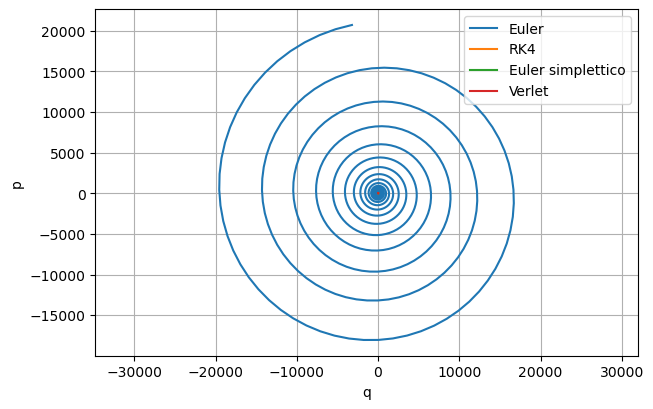

In [28]:
q0,p0=1.0,0.0
h=0.1; T=200.0; nsteps=int(T/h)

ts_e, z_e = euler(harmonic, 0.0, [q0,p0], h, nsteps)
ts_r, z_r = rk4(harmonic, 0.0, [q0,p0], h, nsteps)
z_s = symplectic_euler(q0,p0,h,nsteps)
z_v = verlet(q0,p0,h,nsteps)

plt.plot(z_e[:,0], z_e[:,1], label='Euler')
plt.plot(z_r[:,0], z_r[:,1], label='RK4')
plt.plot(z_s[:,0], z_s[:,1], label='Euler simplettico')
plt.plot(z_v[:,0], z_v[:,1], label='Verlet')
plt.xlabel('q'); plt.ylabel('p'); plt.axis('equal'); plt.legend(); plt.grid(True); plt.show()


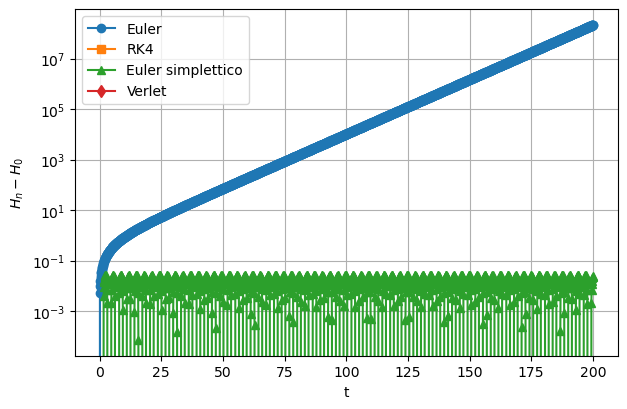

In [ ]:
t = np.linspace(0,T,nsteps+1)
H0=0.5
plt.semilogy(t, energy(z_e)-H0, label='Euler',marker='o', markevery=5)
plt.semilogy(t, energy(z_r)-H0, label='RK4',marker='s', markevery=5)
plt.semilogy(t, energy(z_s)-H0, label='Euler simplettico',marker='^', markevery=5)
plt.semilogy(t, energy(z_v)-H0, label='Verlet',marker='d', markevery=5)
plt.xlabel('t'); plt.ylabel(r'$H_n-H_0$'); plt.legend(); plt.grid(True); plt.show()


### Commento

Euler esplicito modifica qualitativamente la dinamica e genera una spirale verso l'esterno. RK4 è molto accurato per tempi moderati, ma non è simplettico. Euler simplettico e Verlet non conservano esattamente l'energia, ma mostrano tipicamente un errore energetico limitato e oscillante. Verlet, essendo di ordine due e simplettico, combina buona accuratezza e buon comportamento qualitativo a lungo termine.
